# Loan Default Prediction for a Lending Company
**Course:** Predictive Analytics &nbsp;|&nbsp; **Process:** KDD (Knowledge Discovery in Databases)

**Business problem.** A lending company loses money when borrowers stop repaying. Screening is slow and inconsistent, so the company wants to estimate, from each borrower's profile and recent repayment behaviour, who is likely to default in the coming months, so that collections and credit policy can act early.

**Data (three files).**

| File | Content | Grain |
|---|---|---|
| `user_info.csv` | Borrower profile: age, gender, family size, education and career years, loan amount, monthly expense, contract type, province, group, history type, registration date | one row per borrower (128,181) |
| `past_months.csv` | Monthly `default_value` for Jul 2012 to Dec 2012 | borrower x month (6 months) |
| `next_months.csv` | Monthly `default_value` for Jan 2013 to Nov 2013 | borrower x month (11 months), 95,325 borrowers |

**KDD stages in this notebook:** 1 Selection, 2 Preprocessing, 3 Transformation, 4 Data Mining, 5 Interpretation and Evaluation, 6 Deployment (scoring borrowers who have no future data).

In [1]:
import warnings, joblib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
# Folder with the three CSVs. Change this if you run the notebook on your own computer.
DATA = Path("/mnt/user-data/uploads") if Path("/mnt/user-data/uploads").exists() else Path(".")
OUT  = Path("/mnt/user-data/outputs")  if Path("/mnt/user-data/outputs").exists()  else Path("outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font="serif")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "black", "axes.titleweight": "bold"})
def savefig(name): plt.savefig(OUT / "figures" / name, dpi=200, bbox_inches="tight")

## Stage 1: Selection
Load the three tables, understand their structure and **define the prediction target**.

In [2]:
user = pd.read_csv(DATA / "user_info.csv").drop(columns="Unnamed: 0")
past = pd.read_csv(DATA / "past_months.csv").drop(columns="Unnamed: 0")
nxt  = pd.read_csv(DATA / "next_months.csv").drop(columns="Unnamed: 0")

summary = pd.DataFrame({
    "rows": [len(user), len(past), len(nxt)],
    "borrowers": [user.user_id.nunique(), past.user_id.nunique(), nxt.user_id.nunique()],
    "months": ["-", f"{past.month.min()} to {past.month.max()}", f"{nxt.month.min()} to {nxt.month.max()}"]},
    index=["user_info", "past_months", "next_months"])
display(summary)
display(user.head(3).T)

,rows,borrowers,months
user_info,128181,128181,-
past_months,769086,128181,2012-07-01 to 2012-12-01
next_months,1048575,95325,2013-01-01 to 2013-11-01


,0,1,2
registration_date,2012-01-21,2012-01-21,2012-01-21
years_of_study,1.0,8.0,NaN
family_size,0.0,0.0,0.0
loan_amount,187956,170049,108378
total_career_years,3.0,0.0,NaN
birth_date,1987-10-15,1982-04-27,1969-08-30
contract_type,A,B,C
is_male,0.0,1.0,1.0
province,A,A,A
zip_code,300057,300095,300051


### Target definition
`default_value` behaves like an **overdue-instalment counter**: it is 0 for a borrower who is up to date, rises by 1 for each month a payment is missed, and falls back when the borrower catches up (month-to-month changes are almost always 0 or +1). The data has no written definition, so this is an interpretation, and it is the main assumption of the project.

**Target (`default_flag`)** = 1 if the borrower reaches `default_value >= 3` (about three missed payments) at any point in the next 11 months (Jan to Nov 2013), else 0. A threshold of 3 separates serious delinquency from the one-month slips that are common and usually recover. The sensitivity table below shows the model also works for other cut-offs.

Borrowers with no rows in `next_months.csv` have no outcome, so they cannot be used for training. They are kept as a **scoring set** for Stage 6.

In [3]:
DEFAULT_AT = 3
nxt_max = nxt.groupby("user_id").default_value.max()
labelled_ids = nxt_max.index
y_all = (nxt_max >= DEFAULT_AT).astype(int).rename("default_flag")

print(f"Borrowers with an observed outcome (modelling set): {len(labelled_ids):,}")
print(f"Borrowers without future data (scoring set):        {(~user.user_id.isin(labelled_ids)).sum():,}")
print(f"Default rate in modelling set (default_value >= {DEFAULT_AT}): {y_all.mean():.1%}")

sens = pd.DataFrame({"definition": [f"max default_value >= {k}" for k in (1, 2, 3, 4, 6)],
                     "default_rate": [(nxt_max >= k).mean() for k in (1, 2, 3, 4, 6)]})
sens["default_rate"] = sens.default_rate.map("{:.1%}".format)
display(sens)

Borrowers with an observed outcome (modelling set): 95,325
Borrowers without future data (scoring set):        32,856
Default rate in modelling set (default_value >= 3): 12.8%


,definition,default_rate
0,max default_value >= 1,28.3%
1,max default_value >= 2,17.9%
2,max default_value >= 3,12.8%
3,max default_value >= 4,8.8%
4,max default_value >= 6,5.1%


## Stage 2: Preprocessing
Audit the data for missing values, impossible values and duplicates, then clean it. Every cleaning rule is stated so that it can be justified in the report.

In [4]:
miss = user.isna().sum()
miss = pd.DataFrame({"missing": miss, "percent": (miss / len(user) * 100).round(1)}).query("missing > 0")
display(miss)

print("Duplicate borrowers in user_info:", user.user_id.duplicated().sum())
print("Duplicate borrower-month rows:   ", past.duplicated(["user_id","month"]).sum(), "(past),", nxt.duplicated(["user_id","month"]).sum(), "(next)")
print("zip_code below 0 (invalid):      ", (user.zip_code < 0).sum())
print("monthly_expense equal to 0:      ", (user.monthly_expense == 0).sum())
print("monthly_expense above 200,000:   ", (user.monthly_expense > 200_000).sum(), "| maximum:", int(user.monthly_expense.max()))
print("family_size above 10:            ", (user.family_size > 10).sum(), "| maximum:", user.family_size.max())
print("years_of_study > age - 4:        ", (user.years_of_study > user.age - 4).sum())
print("total_career_years > age - 14:   ", (user.total_career_years > user.age - 14).sum())
print("Education/career both missing:   ", (user.years_of_study.isna() & user.total_career_years.isna()).mean().round(3))

,missing,percent
years_of_study,85372,66.6
family_size,9,0.0
total_career_years,85374,66.6
birth_date,37,0.0
is_male,7,0.0
age,37,0.0
group,37,0.0
history_type,176,0.1
monthly_expense,37,0.0


Duplicate borrowers in user_info: 0
Duplicate borrower-month rows:    0 (past), 0 (next)
zip_code below 0 (invalid):       20
monthly_expense equal to 0:       6
monthly_expense above 200,000:    45 | maximum: 1500000
family_size above 10:             39 | maximum: 44.0
years_of_study > age - 4:         21
total_career_years > age - 14:    603
Education/career both missing:    0.666


**Cleaning rules**

| Issue | Rule | Reason |
|---|---|---|
| `years_of_study`, `total_career_years` missing for about two thirds of borrowers | keep as missing and add a flag `has_edu_career_info`; median-impute inside the model pipeline | missingness may itself carry information (for example a different application channel) |
| Study or career years that are impossible for the borrower's age | set to missing | domain rule: study cannot exceed age - 4, career cannot exceed age - 14 |
| `family_size` up to 44 | cap at 10 | extreme values are data-entry errors |
| `monthly_expense` extreme values and zeros | log transform, add `expense_zero` flag | reduces skew without deleting borrowers |
| `age`, `group`, `monthly_expense` missing for 37 borrowers | median or "Unknown" | 0.03 percent of rows |
| `history_type` missing (176) | "Unknown" category | keep the rows |
| `zip_code` (contains -100000) and `birth_date` | dropped | zip code is an identifier-like code with invalid values and `province` already captures location; `age` replaces `birth_date` |

In [5]:
def clean_users(u):
    u = u.copy()
    u["registration_date"] = pd.to_datetime(u["registration_date"])
    u["has_edu_career_info"] = u.years_of_study.notna().astype(int)
    u.loc[u.years_of_study > u.age - 4, "years_of_study"] = np.nan
    u.loc[u.total_career_years > u.age - 14, "total_career_years"] = np.nan
    u["family_size"] = u.family_size.clip(upper=10)
    for c in ["group", "history_type"]:
        u[c] = u[c].fillna("Unknown")
    return u.drop(columns=["zip_code", "birth_date"]).set_index("user_id")

user_c = clean_users(user)
print(user_c.shape)

(128181, 13)


### Exploratory data analysis

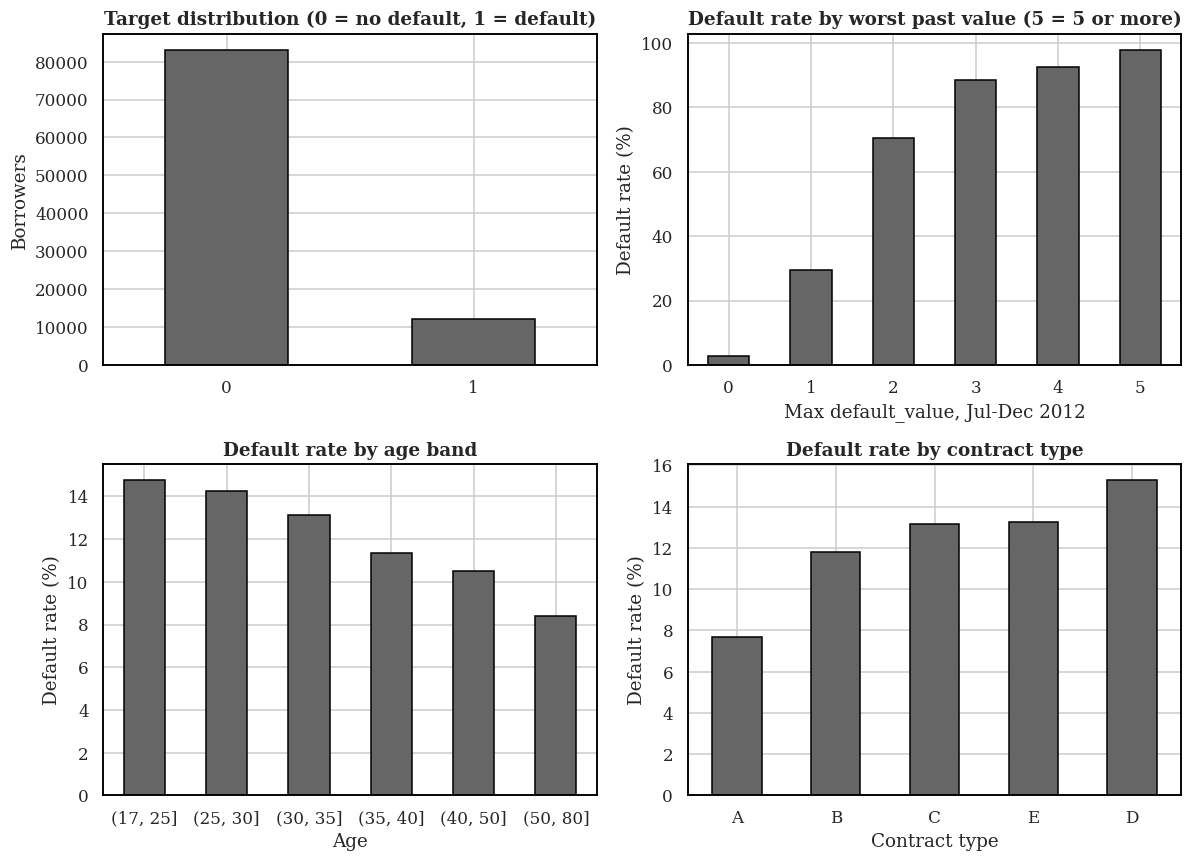

In [6]:
pw = past.pivot(index="user_id", columns="month", values="default_value")
eda = user_c.join(y_all, how="inner").join(pw.max(axis=1).rename("past_max"))

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
y_all.value_counts().sort_index().plot.bar(ax=ax[0,0], color="0.4", edgecolor="black", rot=0)
ax[0,0].set_title("Target distribution (0 = no default, 1 = default)"); ax[0,0].set_xlabel(""); ax[0,0].set_ylabel("Borrowers")

past_rate = eda.groupby(eda.past_max.clip(upper=5)).default_flag.mean() * 100
past_rate.plot.bar(ax=ax[0,1], color="0.4", edgecolor="black", rot=0)
ax[0,1].set_title("Default rate by worst past value (5 = 5 or more)"); ax[0,1].set_xlabel("Max default_value, Jul-Dec 2012"); ax[0,1].set_ylabel("Default rate (%)")

eda["age_band"] = pd.cut(eda.age, [17, 25, 30, 35, 40, 50, 80])
(eda.groupby("age_band", observed=True).default_flag.mean() * 100).plot.bar(ax=ax[1,0], color="0.4", edgecolor="black", rot=0)
ax[1,0].set_title("Default rate by age band"); ax[1,0].set_xlabel("Age"); ax[1,0].set_ylabel("Default rate (%)")

(eda.groupby("contract_type").default_flag.mean() * 100).sort_values().plot.bar(ax=ax[1,1], color="0.4", edgecolor="black", rot=0)
ax[1,1].set_title("Default rate by contract type"); ax[1,1].set_xlabel("Contract type"); ax[1,1].set_ylabel("Default rate (%)")
plt.tight_layout(); savefig("fig_eda.png"); plt.show()

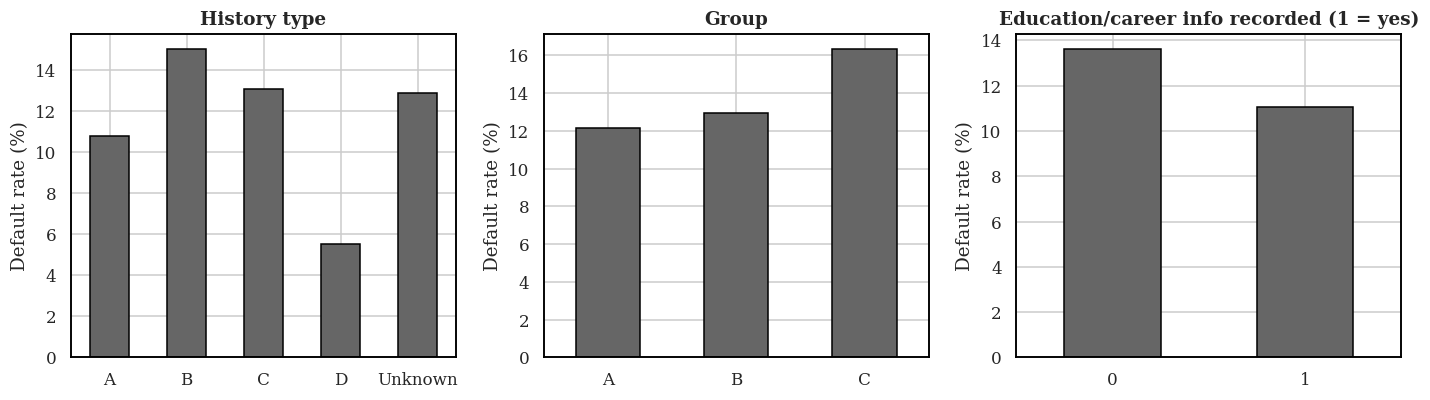

Province default rate: lowest 0.0 | highest 0.227
Loan amount, defaulters vs others (median): {0: 151545.0, 1: 152187.0}


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, col, ttl in zip(ax, ["history_type", "group", "has_edu_career_info"], ["History type", "Group", "Education/career info recorded (1 = yes)"]):
    (eda.groupby(col).default_flag.agg(["mean", "size"]).query("size >= 100")["mean"] * 100).plot.bar(ax=a, color="0.4", edgecolor="black", rot=0)
    a.set_title(ttl); a.set_xlabel(""); a.set_ylabel("Default rate (%)")
plt.tight_layout(); savefig("fig_eda2.png"); plt.show()

prov = eda.groupby("province").default_flag.agg(["mean", "size"]).sort_values("mean")
print("Province default rate: lowest", prov["mean"].iloc[0].round(3), "| highest", prov["mean"].iloc[-1].round(3))
print("Loan amount, defaulters vs others (median):", eda.groupby("default_flag").loan_amount.median().to_dict())

## Stage 3: Transformation
Create model-ready features.

* **Repayment-behaviour features** from the six past months: each month's value, worst value, mean, sum, last value, recent versus early average (trend), number of late months, number of months with value 2 or more, and months since the last late month.
* **Profile features**: age, gender, family size, education and career years, loan amount, log monthly expense, loan-to-expense ratio, tenure (registration to Jan 2013).
* **Encoding**: one-hot for contract type, province, group and history type (rare levels are grouped); median imputation; standardisation for Logistic Regression only.
* **Class imbalance**: handled with class weights and threshold tuning rather than SMOTE. Synthetic rows are unnecessary with 12 to 13 thousand real defaulters and can distort probabilities.
* **Split**: stratified 80/20 train and test split of the labelled borrowers. The test set is touched only once, in Stage 5. Each borrower is one row and features use only 2012 data while the target uses only 2013 data, so there is **no time leakage**.

In [8]:
def build_features(u, past_df):
    pw = past_df.pivot(index="user_id", columns="month", values="default_value").sort_index(axis=1)
    pw.columns = [f"past_m{i}" for i in range(1, 7)]          # m1 = Jul 2012 ... m6 = Dec 2012
    f = pw.copy()
    f["past_max"]  = pw.max(axis=1)
    f["past_mean"] = pw.mean(axis=1)
    f["past_sum"]  = pw.sum(axis=1)
    f["past_last"] = pw["past_m6"]
    f["past_trend"] = pw[["past_m4","past_m5","past_m6"]].mean(axis=1) - pw[["past_m1","past_m2","past_m3"]].mean(axis=1)
    f["past_months_late"] = (pw > 0).sum(axis=1)
    f["past_months_ge2"]  = (pw >= 2).sum(axis=1)
    late = (pw.values > 0)
    f["months_since_late"] = np.where(late.any(axis=1), np.argmax(late[:, ::-1], axis=1), 6)

    X = u.join(f, how="inner")
    X["log_monthly_expense"] = np.log1p(X.monthly_expense)
    X["expense_zero"] = (X.monthly_expense == 0).astype(int)
    X["log_loan_to_expense"] = np.log1p(X.loan_amount / X.monthly_expense.replace(0, np.nan))
    X["tenure_months"] = (pd.Timestamp("2013-01-01") - X.registration_date).dt.days / 30.4
    X["reg_month"] = X.registration_date.dt.month
    return X.drop(columns=["registration_date", "monthly_expense"])

X_all = build_features(user_c, past)
num_cols = [c for c in X_all.columns if c not in ["contract_type", "province", "group", "history_type"]]
cat_cols = ["contract_type", "province", "group", "history_type"]
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical features")
display(X_all[num_cols].describe().T[["mean", "std", "min", "max"]].round(2))

26 numeric + 4 categorical features


,mean,std,min,max
years_of_study,6.20,6.14,0.00,50.00
family_size,1.04,1.37,0.00,10.00
loan_amount,149102.53,19388.36,58245.00,301539.00
total_career_years,6.25,6.28,0.00,45.00
is_male,0.91,0.29,0.00,1.00
age,33.37,9.59,18.00,71.00
has_edu_career_info,0.33,0.47,0.00,1.00
past_m1,0.06,0.35,0.00,6.00
past_m2,0.09,0.45,0.00,7.00
past_m3,0.12,0.54,0.00,8.00


In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

X_lab = X_all.loc[labelled_ids]
y_lab = y_all.loc[labelled_ids]
X_train, X_test, y_train, y_test = train_test_split(X_lab, y_lab, test_size=0.20, stratify=y_lab, random_state=RANDOM_STATE)
print(f"Train {X_train.shape}, default rate {y_train.mean():.2%}   |   Test {X_test.shape}, default rate {y_test.mean():.2%}")

ohe = lambda: OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False)
pre_tree = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_cols), ("cat", ohe(), cat_cols)])
pre_lr   = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols), ("cat", ohe(), cat_cols)])

Train (76260, 30), default rate 12.79%   |   Test (19065, 30), default rate 12.78%


## Stage 4: Data Mining
Four model families are compared with **stratified 5-fold cross-validation on the training set only**: Logistic Regression (interpretable baseline), Decision Tree, Random Forest and LightGBM (gradient boosting). Out-of-fold predictions are kept so that decision thresholds can be chosen without looking at the test set. The best model is then tuned with randomised search.

In [10]:
import time
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
ratio = neg / pos
lgbm_kw = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
               colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)

models = {
    "Logistic Regression": Pipeline([("pre", pre_lr),   ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, C=1.0))]),
    "Decision Tree":       Pipeline([("pre", pre_tree), ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest":       Pipeline([("pre", pre_tree), ("clf", RandomForestClassifier(n_estimators=120, max_depth=12, min_samples_leaf=30, class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE))]),
    "LightGBM (no weights)":   Pipeline([("pre", pre_tree), ("clf", LGBMClassifier(**lgbm_kw))]),
    "LightGBM (class weight)": Pipeline([("pre", pre_tree), ("clf", LGBMClassifier(scale_pos_weight=ratio, **lgbm_kw))]),
}

skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
def cv_oof(model, X, y):
    oof, aucs, aps = np.zeros(len(y)), [], []
    for tr, va in skf.split(X, y):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p; aucs.append(roc_auc_score(y.iloc[va], p)); aps.append(average_precision_score(y.iloc[va], p))
    return oof, np.array(aucs), np.array(aps)

oof, cv_rows = {}, []
for name, m in models.items():
    t = time.time(); oof[name], a, p = cv_oof(m, X_train, y_train)
    cv_rows.append({"Model": name, "CV ROC-AUC": f"{a.mean():.4f} +/- {a.std():.4f}", "CV PR-AUC": f"{p.mean():.4f} +/- {p.std():.4f}", "_auc": a.mean(), "_ap": p.mean()})
    print(f"{name:26s} ROC-AUC {a.mean():.4f}  PR-AUC {p.mean():.4f}  ({time.time()-t:.0f}s)")
cv_table = pd.DataFrame(cv_rows)
display(cv_table.drop(columns=["_auc", "_ap"]))

Logistic Regression        ROC-AUC 0.9052  PR-AUC 0.7403  (6s)


Decision Tree              ROC-AUC 0.8959  PR-AUC 0.6964  (4s)


Random Forest              ROC-AUC 0.9056  PR-AUC 0.7419  (40s)


LightGBM (no weights)      ROC-AUC 0.9062  PR-AUC 0.7443  (14s)


LightGBM (class weight)    ROC-AUC 0.9044  PR-AUC 0.7424  (14s)


,Model,CV ROC-AUC,CV PR-AUC
0,Logistic Regression,0.9052 +/- 0.0049,0.7403 +/- 0.0058
1,Decision Tree,0.8959 +/- 0.0043,0.6964 +/- 0.0064
2,Random Forest,0.9056 +/- 0.0054,0.7419 +/- 0.0069
3,LightGBM (no weights),0.9062 +/- 0.0054,0.7443 +/- 0.0072
4,LightGBM (class weight),0.9044 +/- 0.0058,0.7424 +/- 0.0076


### Hyperparameter tuning
Randomised search with 3-fold cross-validation on the training set, scored by PR-AUC (more informative than ROC-AUC when defaults are the minority class). The search also decides whether class weighting helps.

In [11]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

base = Pipeline([("pre", pre_tree), ("clf", LGBMClassifier(**{k: v for k, v in lgbm_kw.items() if k not in ("n_estimators","learning_rate","num_leaves","min_child_samples","subsample","colsample_bytree")}))])
space = {"clf__n_estimators": randint(150, 600), "clf__learning_rate": uniform(0.02, 0.10), "clf__num_leaves": randint(8, 64),
         "clf__min_child_samples": randint(20, 200), "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
         "clf__reg_lambda": uniform(0, 10), "clf__scale_pos_weight": [1.0, np.sqrt(ratio), ratio]}
search = RandomizedSearchCV(base, space, n_iter=12, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            scoring="average_precision", random_state=RANDOM_STATE, n_jobs=1, refit=False)
t = time.time(); search.fit(X_train, y_train)
print(f"Search finished in {time.time()-t:.0f}s. Best 3-fold PR-AUC: {search.best_score_:.4f}")
best_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
print(best_params)

tuned = Pipeline([("pre", pre_tree), ("clf", LGBMClassifier(**{**lgbm_kw, **best_params}))])
models["LightGBM (tuned)"] = tuned
oof["LightGBM (tuned)"], a, p = cv_oof(tuned, X_train, y_train)
cv_table = pd.concat([cv_table, pd.DataFrame([{"Model": "LightGBM (tuned)", "CV ROC-AUC": f"{a.mean():.4f} +/- {a.std():.4f}", "CV PR-AUC": f"{p.mean():.4f} +/- {p.std():.4f}", "_auc": a.mean(), "_ap": p.mean()}])], ignore_index=True)
display(cv_table.drop(columns=["_auc", "_ap"]))

Search finished in 128s. Best 3-fold PR-AUC: 0.7449
{'colsample_bytree': np.float64(0.7713480415791243), 'learning_rate': np.float64(0.034092422497476266), 'min_child_samples': 34, 'n_estimators': 450, 'num_leaves': 8, 'reg_lambda': np.float64(0.1563640674119393), 'scale_pos_weight': 1.0, 'subsample': np.float64(0.908897907718663)}


,Model,CV ROC-AUC,CV PR-AUC
0,Logistic Regression,0.9052 +/- 0.0049,0.7403 +/- 0.0058
1,Decision Tree,0.8959 +/- 0.0043,0.6964 +/- 0.0064
2,Random Forest,0.9056 +/- 0.0054,0.7419 +/- 0.0069
3,LightGBM (no weights),0.9062 +/- 0.0054,0.7443 +/- 0.0072
4,LightGBM (class weight),0.9044 +/- 0.0058,0.7424 +/- 0.0076
5,LightGBM (tuned),0.9065 +/- 0.0054,0.7444 +/- 0.0066


## Stage 5: Interpretation and Evaluation
All models are refitted on the full training set and scored once on the held-out **test set**. Accuracy is not used as the main metric because 87 percent of borrowers do not default, so a model that predicts "no default" for everyone would already look 87 percent accurate.

Decision thresholds are chosen from the **training out-of-fold predictions** (never from the test set):
* **F1 threshold**: balances precision and recall.
* **Cost threshold**: a missed defaulter (false negative) is assumed to cost **5 times** as much as wrongly flagging a good borrower (false positive). This ratio is an assumption; change `COST_FN` and `COST_FP` to match the lender's real numbers.

In [12]:
from sklearn.metrics import (precision_recall_curve, roc_curve, precision_score, recall_score, f1_score, confusion_matrix)
COST_FN, COST_FP = 5, 1

def f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p); f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[np.nanargmax(f1[:-1])]
def cost_at(y, p, t):
    pred = p >= t; return COST_FP * ((pred) & (y == 0)).sum() + COST_FN * ((~pred) & (y == 1)).sum()
def cost_threshold(y, p):
    grid = np.unique(np.quantile(p, np.linspace(0.0, 0.999, 500)))
    return grid[int(np.argmin([cost_at(y.values, p, t) for t in grid]))]

fitted, test_p, thr_f1, thr_cost, rows = {}, {}, {}, {}, []
for name, m in models.items():
    fitted[name] = clone(m).fit(X_train, y_train)
    test_p[name] = fitted[name].predict_proba(X_test)[:, 1]
    thr_f1[name], thr_cost[name] = f1_threshold(y_train, oof[name]), cost_threshold(y_train, oof[name])
    pred = test_p[name] >= thr_f1[name]
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, test_p[name]), "PR-AUC": average_precision_score(y_test, test_p[name]),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "Expected cost": cost_at(y_test.values, test_p[name], thr_cost[name])})
results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))
print("Precision, Recall and F1 use the F1-optimal threshold chosen on training out-of-fold predictions.")
print(f"Test prevalence: {y_test.mean():.2%}  (random model PR-AUC would be about {y_test.mean():.3f})")

,ROC-AUC,PR-AUC,Precision,Recall,F1,Expected cost
Model,,,,,,
Logistic Regression,0.9083,0.7482,0.6383,0.7300,0.6811,3899
Decision Tree,0.9023,0.7032,0.6154,0.7538,0.6776,3917
Random Forest,0.9101,0.7513,0.6361,0.7382,0.6834,3853
LightGBM (no weights),0.9077,0.7486,0.6592,0.7000,0.6790,3849
LightGBM (class weight),0.9096,0.7521,0.6311,0.7419,0.6820,3865
LightGBM (tuned),0.9100,0.7529,0.6428,0.7304,0.6838,3824


Precision, Recall and F1 use the F1-optimal threshold chosen on training out-of-fold predictions.
Test prevalence: 12.78%  (random model PR-AUC would be about 0.128)


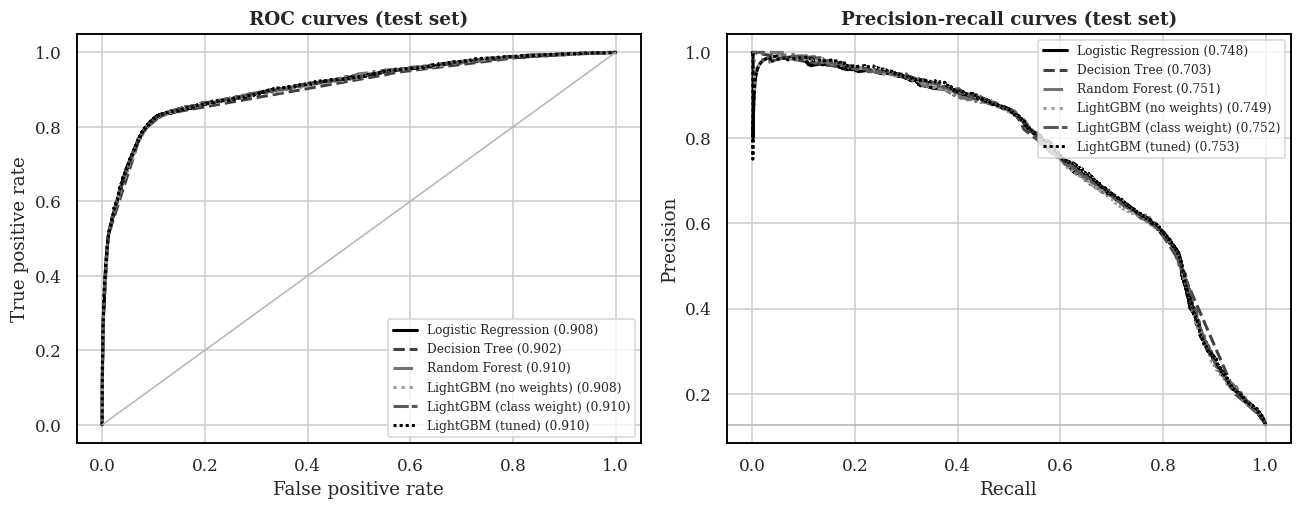

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
styles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (1, 1))]
shades = ["0.0", "0.25", "0.45", "0.6", "0.35", "0.0"]
for (name, p), ls, sh in zip(test_p.items(), styles, shades):
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, ls=ls, color=sh, lw=2, label=f"{name} ({results.loc[name,'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, ls=ls, color=sh, lw=2, label=f"{name} ({results.loc[name,'PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], color="0.7", lw=1); ax[0].set(title="ROC curves (test set)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(y_test.mean(), color="0.7", lw=1); ax[1].set(title="Precision-recall curves (test set)", xlabel="Recall", ylabel="Precision"); ax[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); savefig("fig_roc_pr.png"); plt.show()

Selected model: LightGBM (tuned)


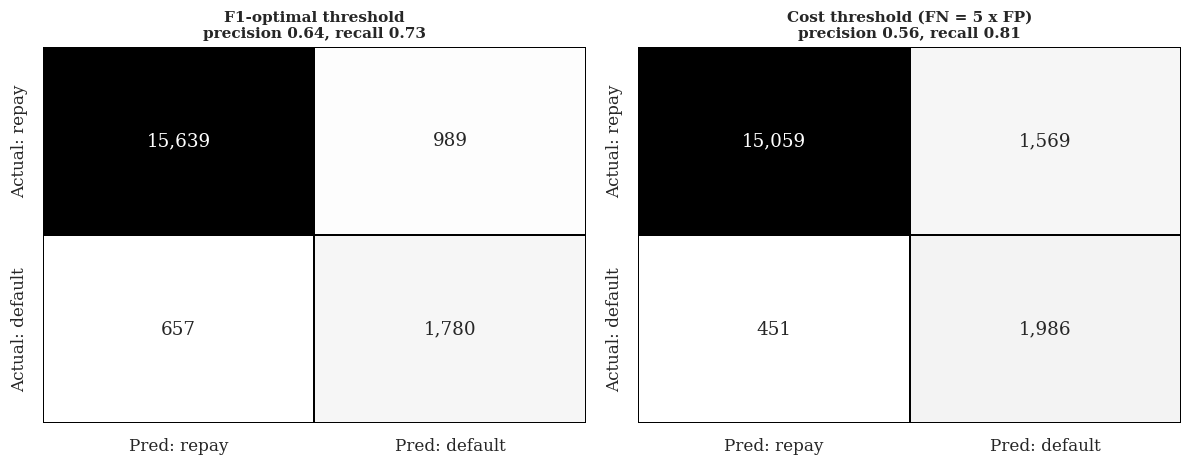

,Policy,Expected cost (units),Saving vs approve-all
0,Approve everyone (flag nobody),12185,0.0%
1,Flag everyone,16628,-36.5%
2,LightGBM (tuned) at cost threshold,3824,68.6%


In [14]:
# Select the final model by cross-validated PR-AUC (training data only)
best_name = cv_table.sort_values("_ap", ascending=False).iloc[0]["Model"]
final = fitted[best_name]; p_final = test_p[best_name]
print("Selected model:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a, (ttl, thr) in zip(ax, [("F1-optimal threshold", thr_f1[best_name]), (f"Cost threshold (FN = {COST_FN} x FP)", thr_cost[best_name])]):
    cm = confusion_matrix(y_test, p_final >= thr)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Greys", cbar=False, ax=a, linewidths=1, linecolor="black",
                xticklabels=["Pred: repay", "Pred: default"], yticklabels=["Actual: repay", "Actual: default"])
    tn, fp, fn, tp = cm.ravel()
    a.set_title(f"{ttl}\nprecision {tp/(tp+fp):.2f}, recall {tp/(tp+fn):.2f}", fontsize=10)
plt.tight_layout(); savefig("fig_confusion.png"); plt.show()

# Business-cost comparison on the test set
t_c = thr_cost[best_name]
cost_model  = cost_at(y_test.values, p_final, t_c)
cost_approve_all = COST_FN * (y_test == 1).sum()      # flag nobody
cost_reject_all  = COST_FP * (y_test == 0).sum()      # flag everybody
display(pd.DataFrame({"Policy": ["Approve everyone (flag nobody)", "Flag everyone", f"{best_name} at cost threshold"],
                      "Expected cost (units)": [cost_approve_all, cost_reject_all, cost_model]}).assign(**{"Saving vs approve-all": lambda d: (1 - d["Expected cost (units)"] / cost_approve_all).map("{:.1%}".format)}))

,borrowers,defaulters,default_rate,share_of_all_defaulters,cumulative_capture,lift
decile,,,,,,
1,1907,1453,76.2%,59.6%,59.6%,5.96
2,1906,567,29.7%,23.3%,82.9%,2.33
3,1907,94,4.9%,3.9%,86.7%,0.39
4,1906,77,4.0%,3.2%,89.9%,0.32
5,1906,61,3.2%,2.5%,92.4%,0.25
6,1907,61,3.2%,2.5%,94.9%,0.25
7,1906,49,2.6%,2.0%,96.9%,0.20
8,1907,42,2.2%,1.7%,98.6%,0.17
9,1906,20,1.0%,0.8%,99.5%,0.08


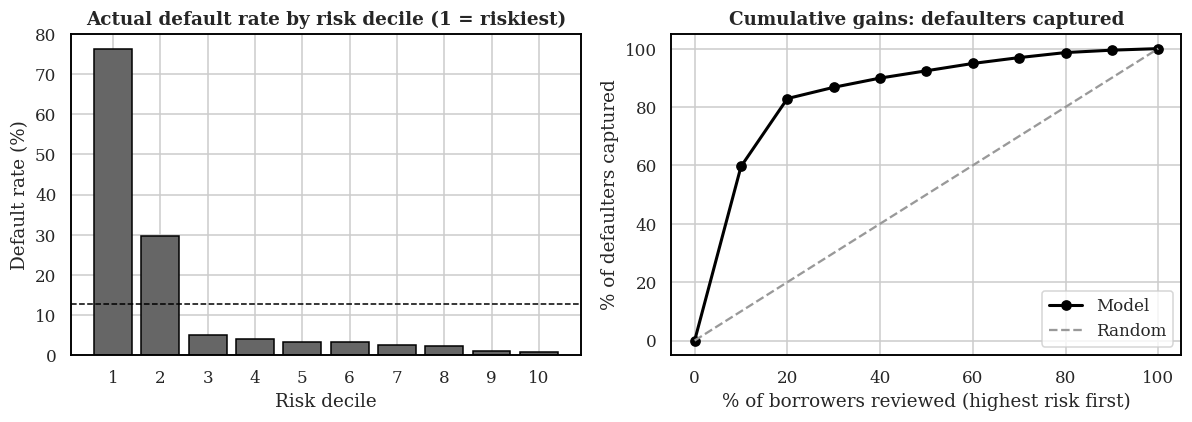

In [15]:
# Lift by risk decile (test set): how well does the score rank borrowers?
dec = pd.DataFrame({"y": y_test.values, "p": p_final})
dec["decile"] = pd.qcut(dec.p.rank(method="first"), 10, labels=range(10, 0, -1)).astype(int)   # 1 = highest risk
tab = dec.groupby("decile").agg(borrowers=("y", "size"), defaulters=("y", "sum"), default_rate=("y", "mean")).sort_index()
tab["share_of_all_defaulters"] = tab.defaulters / tab.defaulters.sum()
tab["cumulative_capture"] = tab.share_of_all_defaulters.cumsum()
tab["lift"] = tab.default_rate / y_test.mean()
display(tab.assign(default_rate=tab.default_rate.map("{:.1%}".format), share_of_all_defaulters=tab.share_of_all_defaulters.map("{:.1%}".format),
                   cumulative_capture=tab.cumulative_capture.map("{:.1%}".format), lift=tab.lift.round(2)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(tab.index, tab.default_rate * 100, color="0.4", edgecolor="black"); ax[0].axhline(y_test.mean() * 100, color="black", ls="--", lw=1)
ax[0].set(title="Actual default rate by risk decile (1 = riskiest)", xlabel="Risk decile", ylabel="Default rate (%)"); ax[0].set_xticks(range(1, 11))
ax[1].plot([0] + list(tab.index * 10), [0] + list(tab.cumulative_capture * 100), color="black", lw=2, marker="o", label="Model")
ax[1].plot([0, 100], [0, 100], color="0.6", ls="--", label="Random"); ax[1].legend()
ax[1].set(title="Cumulative gains: defaulters captured", xlabel="% of borrowers reviewed (highest risk first)", ylabel="% of defaulters captured")
plt.tight_layout(); savefig("fig_gains.png"); plt.show()

### Explaining the model: what drives default?
SHAP values show how each feature pushes an individual prediction towards or away from default.

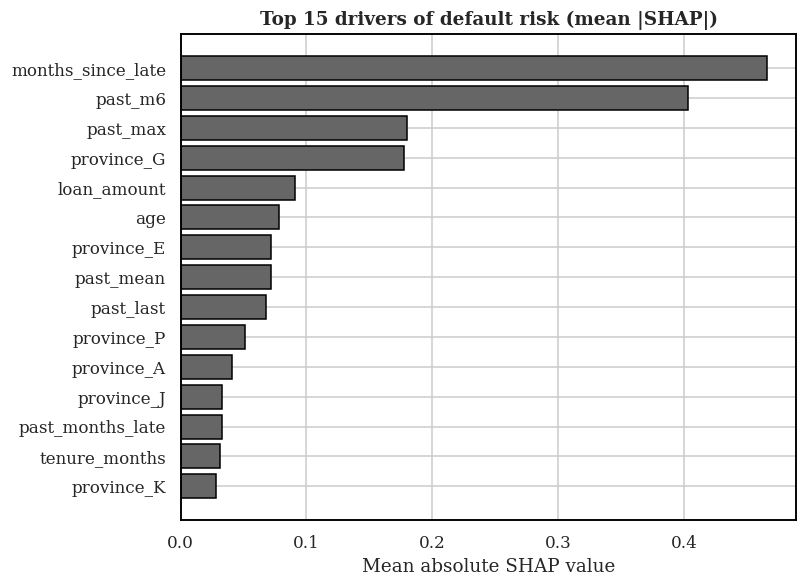

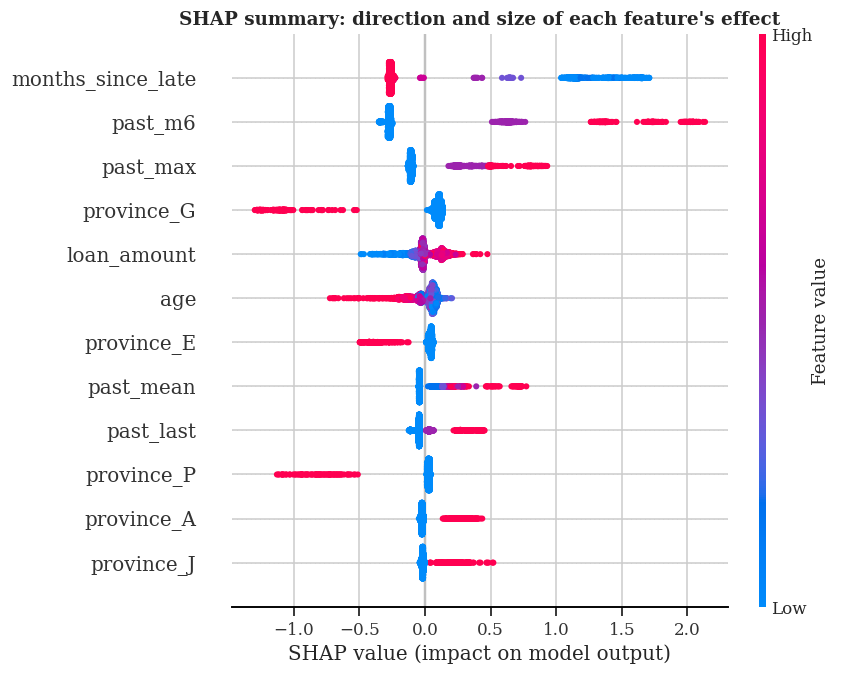

,mean |SHAP|
months_since_late,0.4662
past_m6,0.4030
past_max,0.1796
province_G,0.1776
loan_amount,0.0909
age,0.0782
province_E,0.0722
past_mean,0.0720
past_last,0.0681
province_P,0.0513


In [16]:
import shap
pre_f, clf_f = final.named_steps["pre"], final.named_steps["clf"]
Xt_test = pd.DataFrame(pre_f.transform(X_test), columns=pre_f.get_feature_names_out(), index=X_test.index)
Xt_test.columns = [c.replace("num__", "").replace("cat__", "") for c in Xt_test.columns]
Xs = Xt_test.sample(3000, random_state=RANDOM_STATE)
sv = shap.TreeExplainer(clf_f).shap_values(Xs)
if isinstance(sv, list): sv = sv[1]
if sv.ndim == 3: sv = sv[:, :, 1]

shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=Xs.columns).sort_values(ascending=False)
top = shap_imp.head(15)[::-1]
plt.figure(figsize=(7.5, 5.5)); plt.barh(top.index, top.values, color="0.4", edgecolor="black")
plt.title("Top 15 drivers of default risk (mean |SHAP|)"); plt.xlabel("Mean absolute SHAP value"); plt.tight_layout(); savefig("fig_shap_bar.png"); plt.show()

shap.summary_plot(sv, Xs, max_display=12, show=False); plt.title("SHAP summary: direction and size of each feature's effect")
plt.tight_layout(); savefig("fig_shap_beeswarm.png"); plt.show()
display(shap_imp.head(12).round(4).to_frame("mean |SHAP|"))

In [17]:
# Sensitivity of the result to the way "default" is defined
sens_rows = []
for k in (1, 2, 3, 4):
    yk = (nxt_max >= k).astype(int).loc[labelled_ids]
    yk_tr, yk_te = yk.loc[X_train.index], yk.loc[X_test.index]
    mk = clone(tuned).fit(X_train, yk_tr); pk = mk.predict_proba(X_test)[:, 1]
    sens_rows.append({"Default defined as": f"default_value >= {k}", "Default rate": f"{yk.mean():.1%}", "ROC-AUC": round(roc_auc_score(yk_te, pk), 4), "PR-AUC": round(average_precision_score(yk_te, pk), 4)})
display(pd.DataFrame(sens_rows))

,Default defined as,Default rate,ROC-AUC,PR-AUC
0,default_value >= 1,28.3%,0.8462,0.7893
1,default_value >= 2,17.9%,0.8847,0.7703
2,default_value >= 3,12.8%,0.9100,0.7529
3,default_value >= 4,8.8%,0.9211,0.7102


## Stage 6: Deployment
The 32,856 borrowers with no rows in `next_months.csv` have no known outcome, so the final model scores them to prioritise follow-up. Risk bands use the score distribution of the test set: **High** = top 10 percent, **Medium** = next 20 percent, **Low** = the rest. `risk_score` ranks borrowers; it is not a calibrated probability.

The trained pipeline is saved with `joblib` together with its thresholds, and is served to users by the Streamlit web app in the `deployment/` folder (`app.py`, `scoring.py`, `requirements.txt`).

In [18]:
scoring_ids = user_c.index.difference(labelled_ids)
X_score = X_all.loc[scoring_ids]
score = final.predict_proba(X_score)[:, 1]
q90, q70 = np.quantile(p_final, [0.90, 0.70])
flag_thr = thr_cost[best_name]
out = pd.DataFrame({"user_id": X_score.index, "risk_score": score.round(5),
                    "risk_band": np.where(score >= q90, "High", np.where(score >= q70, "Medium", "Low")),
                    "predicted_default": (score >= flag_thr).astype(int),
                    "loan_amount": X_score.loan_amount.values}).sort_values("risk_score", ascending=False)
out.to_csv(OUT / "borrower_risk_scores.csv", index=False)
print(out.risk_band.value_counts(normalize=True).round(3).to_dict(), "| flagged:", f"{out.predicted_default.mean():.1%}")
display(out.head(8))

joblib.dump({"pipeline": final, "model_name": best_name, "threshold_cost": float(thr_cost[best_name]), "threshold_f1": float(thr_f1[best_name]),
             "band_cutoffs": {"high": float(q90), "medium": float(q70)}, "default_definition": f"max default_value >= {DEFAULT_AT} in next 11 months"},
            OUT / "loan_default_model.joblib")
results.round(4).to_csv(OUT / "model_comparison.csv")

{'Low': 0.648, 'Medium': 0.243, 'High': 0.108} | flagged: 19.4%


,user_id,risk_score,risk_band,predicted_default,loan_amount
1311,807372,0.98948,High,1,141147
8918,871070,0.98881,High,1,123183
11407,893398,0.98763,High,1,125724
1607,809987,0.98759,High,1,151545
6603,850999,0.98726,High,1,161874
11048,890001,0.98709,High,1,143730
17109,943714,0.98685,High,1,155214
15519,931059,0.98683,High,1,123183


In [19]:
from IPython.display import Markdown
r = results.loc[best_name]; cap10 = tab.cumulative_capture.iloc[0]; cap30 = tab.cumulative_capture.iloc[2]
Markdown(f'''
### Summary of results
* **Final model:** {best_name}, selected on cross-validated PR-AUC; test ROC-AUC **{r["ROC-AUC"]:.3f}**, PR-AUC **{r["PR-AUC"]:.3f}** (a random model scores about {y_test.mean():.3f}).
* **Ranking power:** the riskiest 10% of borrowers contain **{cap10:.0%}** of all defaulters and the riskiest 30% contain **{cap30:.0%}**.
* **Top drivers (SHAP):** {", ".join(shap_imp.head(5).index)}.
* **Business cost:** at the cost threshold, expected cost is **{1 - cost_model / cost_approve_all:.0%} lower** than approving everyone without screening (assuming a missed defaulter costs {COST_FN}x a wrongly flagged borrower).
''')


### Summary of results
* **Final model:** LightGBM (tuned), selected on cross-validated PR-AUC; test ROC-AUC **0.910**, PR-AUC **0.753** (a random model scores about 0.128).
* **Ranking power:** the riskiest 10% of borrowers contain **60%** of all defaulters and the riskiest 30% contain **87%**.
* **Top drivers (SHAP):** months_since_late, past_m6, past_max, province_G, loan_amount.
* **Business cost:** at the cost threshold, expected cost is **69% lower** than approving everyone without screening (assuming a missed defaulter costs 5x a wrongly flagged borrower).
